# Apache SpamAssassin Spam Classification - Model Pipeline

Introductory TLDR goes here

## 1. Imports and Loading Packages

In [1]:
from pathlib import Path
import random

from utils import create_train_test_split, clean_emails, evaluate_model, plot_confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.base import clone


seed = 42

## 2. Train Test Split

Since the train test split has already been made, we will skip this step

## 3. Building Data Pipeline

This involves feature engineering, and model building.

For feature engineering, we will choose to either remove the headers altogether or selectively mask the headers. Furthermore, we will also mask the URLs, numbers, etc.
- remove stop words - good for tf-idf

For model building we will use a list of models that is yet to be decided.

In [2]:
DATASPLIT_DIR = Path('./data_split')
RAW_DATA_DIR = Path('./raw_data')

X_train, y_train, X_test, y_test = create_train_test_split(raw_data_dir=RAW_DATA_DIR, data_split_dir=DATASPLIT_DIR, seed=seed)
len(X_train), len(X_test), len(y_train), len(y_test)

(7330, 1835, 7330, 1835)

In [3]:
X_train = clean_emails(emails = X_train, remove_headers=True)

## 4. Feature Engineering

Because the models cannot handle the text data, we will have to convert them into a matrix.

In [4]:
vectorizer = TfidfVectorizer(input='content', lowercase=True, stop_words='english', encoding='latin-1', max_features=10000)

## 4. Model Building

In [5]:
pipe = Pipeline([
    ("vectorizer", vectorizer),
    ("classifier", 'passthrough') # placeholder
])

### Model 1 - Logistic Regression

Logistic regression is a very good linear classification baseline. ```class_weight = 'balanced'``` multiples loss by the weight ($w_{class}$) $$w_{class} = \frac{total\_samples}{number\ of\ classes \times samples\ in\ the\ class}$$ 
This means for the minority class, the weight on the loss would be much more higher compared to the majority class, thus harshly updating the gradient in the case when the minority class prediction is wrong.

Evaluation Metrics for Logistic Regression:
accuracy  : 0.9139
precision : 0.9471
recall    : 0.7098
f1        : 0.8115
roc_auc   : 0.9868


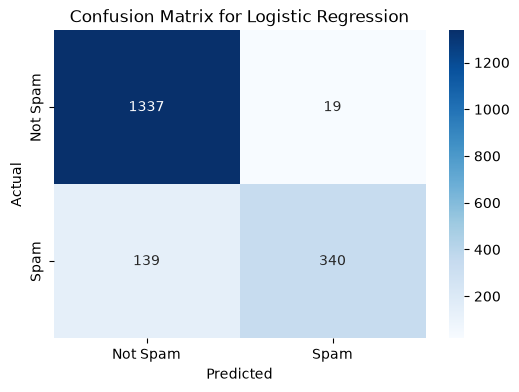

In [6]:
model_name = 'Logistic Regression'
lr = LogisticRegression(max_iter=2000, random_state=seed, class_weight='balanced')
lr_pipe = clone(pipe).set_params(
    classifier = lr
)

lr_pipe.fit(X_train, y_train)
pred_lr = lr_pipe.predict(X_test)
prob_lr = lr_pipe.predict_proba(X_test)[:, 1]

metrics_lr = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_lr, y_prob=prob_lr)
plot_confusion_matrix(y_true = y_test, y_pred = pred_lr, title=f'Confusion Matrix for {model_name}')

### Model 2 - Decision Tree

A single decision tree is a good classifier but can be prone to overfitting (low bias and high variance) on an imbalanced dataset.

Evaluation Metrics for Decision Tree:
accuracy  : 0.8877
precision : 0.9361
recall    : 0.6117
f1        : 0.7399
roc_auc   : 0.7933


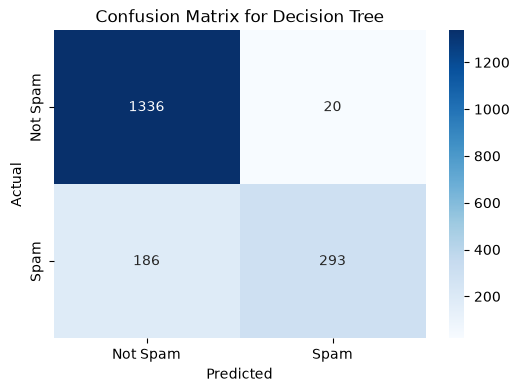

In [7]:
model_name = 'Decision Tree'
dt = DecisionTreeClassifier(random_state=seed, max_depth=8, class_weight='balanced')
dt_pipe = clone(pipe).set_params(
    classifier=dt
)

dt_pipe.fit(X_train, y_train)
pred_dt = dt_pipe.predict(X_test)
prob_dt = dt_pipe.predict_proba(X_test)[:, 1]

metrics_dt = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_dt, y_prob=prob_dt)
plot_confusion_matrix(y_true = y_test, y_pred = pred_dt, title=f'Confusion Matrix for {model_name}')

### Model 3 - Random Forest

Random forest is an ensemble method where different decision trees vote on the output. This ensemble reduces the variance of the model and thus increase the bias. This essentially is an attempt to lower the overfitting in the decision of a single decision tree.

Evaluation Metrics for Decision Tree:
accuracy  : 0.9341
precision : 0.9838
recall    : 0.7599
f1        : 0.8575
roc_auc   : 0.9949


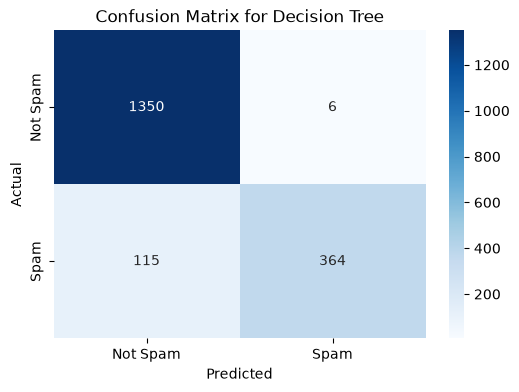

In [8]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1)
rf_pipe = clone(pipe).set_params(
    classifier=rf
)

rf_pipe.fit(X_train, y_train)
pred_rf = rf_pipe.predict(X_test)
prob_rf = rf_pipe.predict_proba(X_test)[:, 1]

metrics_rf = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_rf, y_prob=prob_rf)
plot_confusion_matrix(y_true = y_test, y_pred = pred_rf, title=f'Confusion Matrix for {model_name}')

### Model 4: Multinomial Naive Bayes

Multinomial Naive Bayes is another model that works very well with tf-idf vectors in practice. However, this model is not equipped with handling class imbalance.

Evaluation Metrics for Multinomial Naive Bayes:
accuracy  : 0.8708
precision : 0.8306
recall    : 0.6347
f1        : 0.7195
roc_auc   : 0.9714


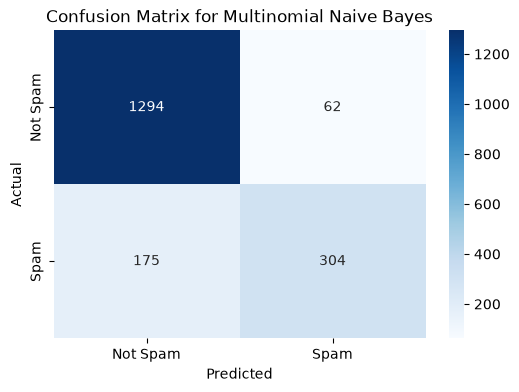

In [10]:
model_name = 'Multinomial Naive Bayes'
nb_multi = MultinomialNB()
nb_pipe = clone(pipe).set_params(
    classifier=nb_multi
)

nb_pipe.fit(X_train, y_train)
pred_nb = nb_pipe.predict(X_test)
prob_nb = nb_pipe.predict_proba(X_test)[:, 1]

metrics_nb = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_nb, y_prob=prob_nb)
plot_confusion_matrix(y_true = y_test, y_pred = pred_nb, title=f'Confusion Matrix for {model_name}')

### Model 5: Xgboost

Evaluation Metrics for Gradient Boosting:
accuracy  : 0.8643
precision : 0.9832
recall    : 0.4885
f1        : 0.6527
roc_auc   : 0.9728


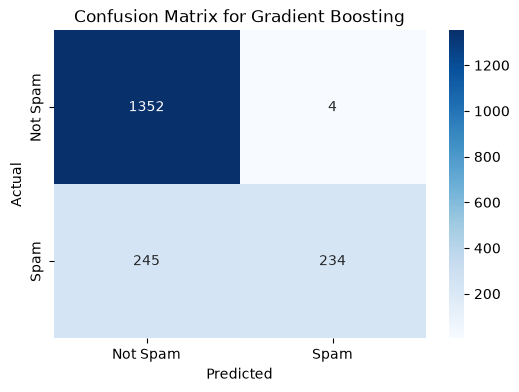

In [11]:
model_name = 'Gradient Boosting'
gb = GradientBoostingClassifier(random_state=seed)
gb_pipe = clone(pipe).set_params(
    classifier=gb
)

gb_pipe.fit(X_train, y_train)
pred_gb = gb_pipe.predict(X_test)
prob_gb = gb_pipe.predict_proba(X_test)[:, 1]

metrics_gb = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_gb, y_prob=prob_gb)
plot_confusion_matrix(y_true = y_test, y_pred = pred_gb, title=f'Confusion Matrix for {model_name}')

### Model 6: SVM

Evaluation Metrics for SVM (RBF Kernel) calibrated:
accuracy  : 0.9183
precision : 0.9796
recall    : 0.7015
f1        : 0.8175
roc_auc   : 0.9943


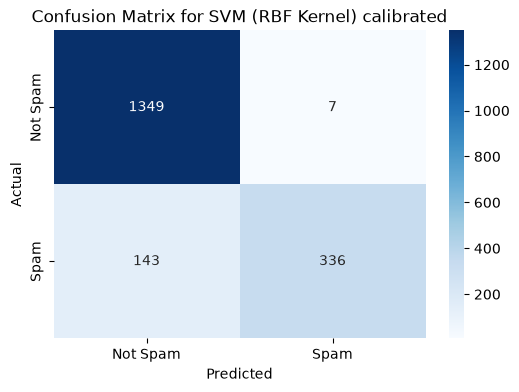

In [12]:
from sklearn.calibration import CalibratedClassifierCV

model_name = 'SVM (RBF Kernel) calibrated'

# svm_rbf = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=seed)
svm_rbf = SVC(kernel='rbf', random_state=seed, class_weight='balanced')
calibrated_svm = CalibratedClassifierCV(estimator=svm_rbf, method='sigmoid', cv=5)
svm_pipe = clone(pipe).set_params(
    classifier=calibrated_svm
)

svm_pipe.fit(X_train, y_train)
pred_svm = svm_pipe.predict(X_test)
prob_svm = svm_pipe.predict_proba(X_test)[:, 1]

metrics_svm = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_svm, y_prob=prob_svm)
plot_confusion_matrix(y_true = y_test, y_pred = pred_svm, title=f'Confusion Matrix for {model_name}')